# Paper figures

The plots follow the styles in the original EDA and hedonic notebooks and use
the current saved photo exports and model specifications. The style references
are `source/eda/EDA_datasets_July1_Aug15.ipynb` and `source/inputs/hedonic_analysis.ipynb`.

Photo counts and scores use the offer recorded in the source photo URLs for each property.

In [1]:
from pathlib import Path
import sys

working_dir = Path.cwd()
root = next(
    (path for path in (working_dir, *working_dir.parents) if (path / "inputs" / "prompts.json").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Open this notebook from the final_project directory or one of its subdirectories.")
sys.path.insert(0, str(root / "code"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils.paper_data import DATASETS_DIR, MARKETS, load_analysis_data
from utils.paper_plots import save_figure

inputs_dir = root / DATASETS_DIR
figure_assets = inputs_dir / "figure_assets"
figures_dir = root / "outputs" / "figures"
listings, photo_types, quality_models_by_type = load_analysis_data(root)
interiors = photo_types["interior"]

## CLIP method and data descriptives

Figures 1–6. Photo counts, dimensions, and metrics come from the saved photo exports.

### Figure 1. CLIP diagram

The training schematic is the artwork from the [published Figure 1](https://arxiv.org/pdf/2608.01544v1#page=4).

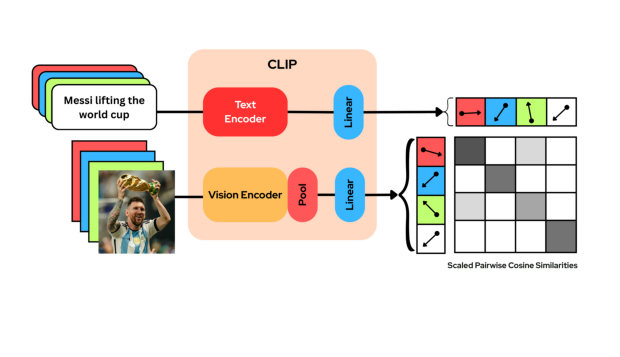

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.375))
ax.imshow(plt.imread(figure_assets / "clip_training_diagram.png"))
ax.set_axis_off()
fig.subplots_adjust(left=0, bottom=0, right=1, top=1)
save_figure(fig, figures_dir, "01")

### Figure 2. Listing creation dates

Plot style from the original EDA notebook, cell 121.

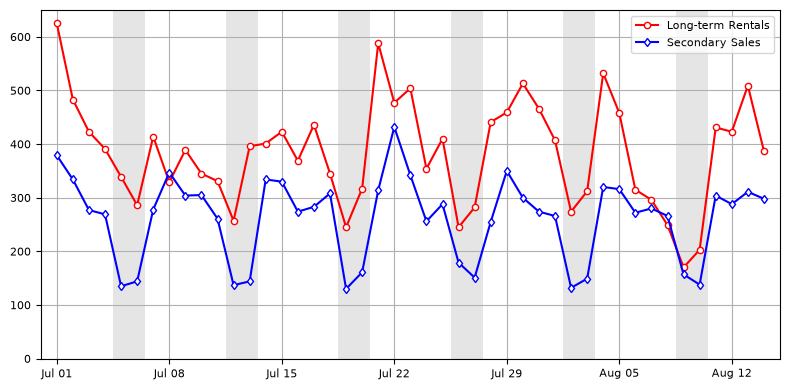

In [4]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(8, 4))
for (market, title), (marker, color) in zip(MARKETS.items(), [("o", "red"), ("d", "blue")]):
    dates = listings.loc[listings["deal_type"].eq(market), "date0"].dt.date
    counts = dates.value_counts().sort_index()
    ax.plot(counts.index, counts.values, label=title, marker=marker, color=color,
            markersize=4.5, markerfacecolor="white")

dates = pd.date_range(listings["date0"].min().normalize(), listings["date0"].max().normalize())
half_day = pd.Timedelta(hours=12)
for date in dates[dates.weekday >= 5]:
    ax.axvspan(date - half_day, date + half_day, color="grey", alpha=0.2, lw=0)

ax.set_xlim(dates[0] - 2 * half_day, dates[-1] + 2 * half_day)
ax.set_ylim(0, 650)
ax.set_xticks(dates[::7])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.tick_params(labelsize=8)
ax.legend(fontsize=8)
ax.grid(True)
fig.tight_layout()
save_figure(fig, figures_dir, "02")

### Figure 3. Images per listing by author type

Plot style from the original EDA notebook, cell 123.

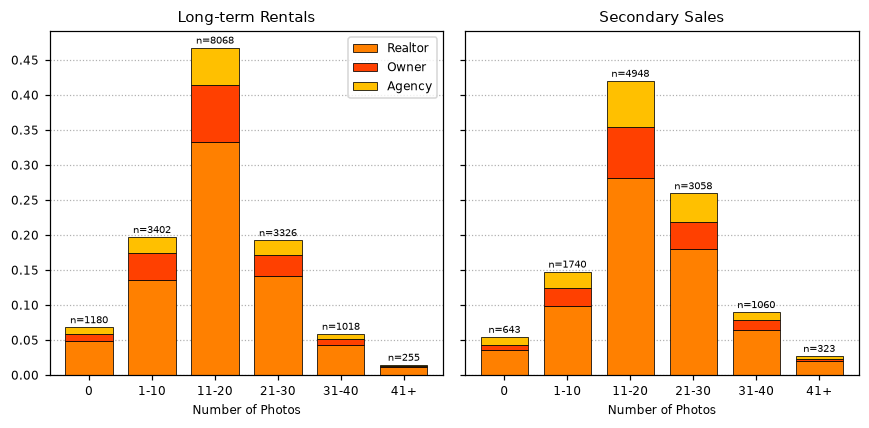

In [5]:
from matplotlib.ticker import MultipleLocator

from utils.paper_data import PHOTO_BINS

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
authors = ["Realtor", "Owner", "Agency"]
palette = sns.color_palette("autumn", n_colors=len(authors))
colors = [palette[1], palette[0], palette[2]]

for ax, (market, title) in zip(axes, MARKETS.items()):
    data = listings.loc[listings["deal_type"].eq(market)]
    shares = pd.crosstab(data["link_num_categ"], data["author_cat"], normalize="all")
    shares = shares.reindex(index=PHOTO_BINS, columns=authors, fill_value=0)
    shares.plot(kind="bar", stacked=True, ax=ax, color=colors, width=0.75,
                linewidth=0.5, edgecolor="black", legend=ax is axes[0])

    counts = data["link_num_categ"].value_counts().reindex(PHOTO_BINS, fill_value=0)
    for i, (height, count) in enumerate(zip(shares.sum(axis=1), counts)):
        ax.annotate(f"n={count}", (i, height), ha="center", va="bottom",
                    xytext=(0, 1), textcoords="offset points", fontsize=6.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Number of Photos", fontsize=8)
    ax.tick_params(axis="x", rotation=0, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.yaxis.set_major_locator(MultipleLocator(0.05))
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle=":")
axes[0].legend(title="", fontsize=8)
fig.tight_layout()
save_figure(fig, figures_dir, "03")

### Figure 4. Property location and number of images

Plot style from the original EDA notebook, cell 129.
The gray outlines use a 0.35 pt stroke to match the published rendering.

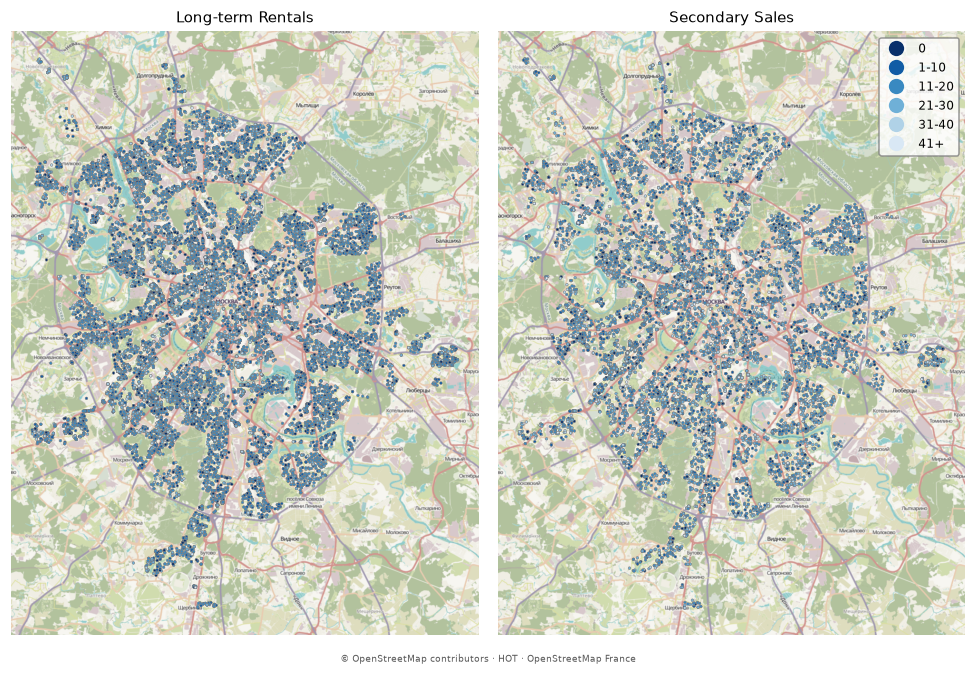

In [6]:
import geopandas as gpd
from matplotlib.colors import ListedColormap

from utils.paper_plots import add_basemap

points = gpd.GeoDataFrame(
    listings, geometry=gpd.points_from_xy(listings["lng"], listings["lat"]), crs=4326,
).to_crs(3857)
cmap = ListedColormap(plt.get_cmap("Blues_r")(np.linspace(0, 0.85, 256)))
missing = {"color": "lightgrey", "edgecolor": "red", "hatch": "///", "label": "Missing values"}

fig, axes = plt.subplots(1, 2, figsize=(9, 6))
for ax, (market, title) in zip(axes, MARKETS.items()):
    data = points.loc[points["deal_type"].eq(market)]
    data.plot(column="link_num_categ", categorical=True, cmap=cmap, ax=ax,
              markersize=3, linewidth=0.35, edgecolor="0.5", legend=ax is axes[1],
              legend_kwds={"fontsize": 8, "edgecolor": "gray"},
              missing_kwds=missing, rasterized=True)
    add_basemap(ax, figure_assets / "moscow_humanitarian.png")
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
fig.text(0.5, 0.02, "© OpenStreetMap contributors · HOT · OpenStreetMap France",
         ha="center", fontsize=6, color="0.35")
fig.tight_layout(rect=(0, 0.035, 1, 1))
save_figure(fig, figures_dir, "04", dpi=400)

### Figure 5. Dimensions of interior images

Plot style from the original EDA notebook, cell 92.

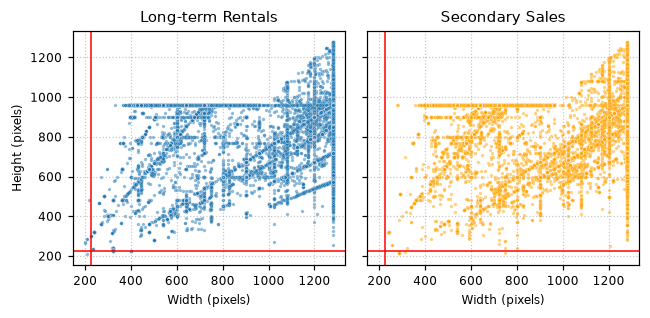

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3), sharex=True, sharey=True)
for ax, (market, title), color in zip(axes, MARKETS.items(), ["tab:blue", "orange"]):
    photos = interiors.loc[interiors["deal_type"].eq(market)].dropna(subset=["width", "height"])
    sns.scatterplot(x="width", y="height", data=photos, ax=ax,
                    alpha=0.5, s=5, color=color, rasterized=True)
    ax.axvline(224, color="red", linewidth=1)
    ax.axhline(224, color="red", linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Width (pixels)", fontsize=8)
    ax.set_ylabel("Height (pixels)", fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.tick_params(labelsize=8)
fig.tight_layout()
save_figure(fig, figures_dir, "05", dpi=400)

### Figure 6. Image quality and CLIP polarity

Plot style from the original EDA notebook, cell 95.

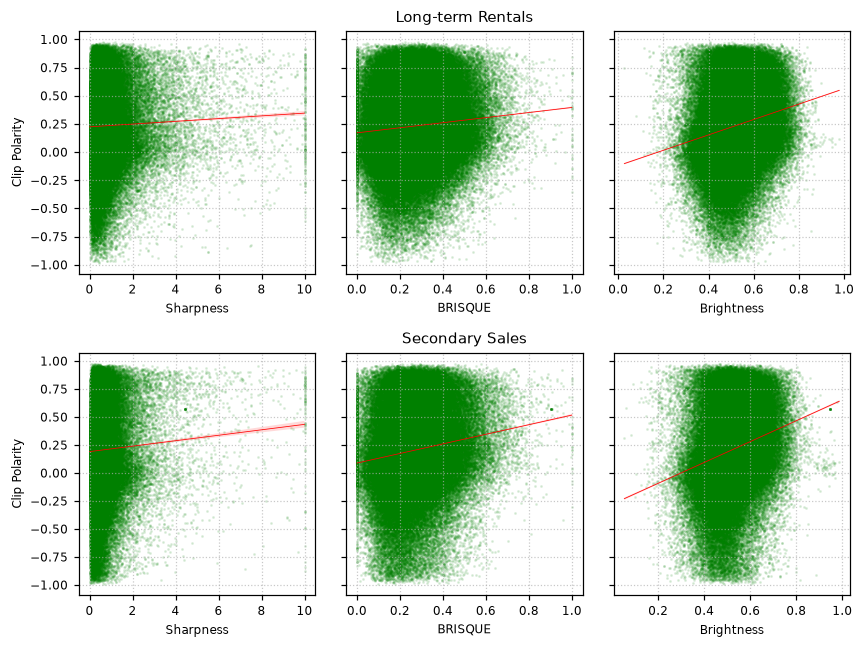

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(8, 6), sharey="row")
finished = interiors.dropna(subset=["clip_polarity_adj"])
scatter_kws = {"alpha": 0.1, "s": 1, "color": "green", "rasterized": True}
line_kws = {"color": "red", "linewidth": 0.5}
quality_metrics = [("sharpness", "Sharpness"), ("brisque", "BRISQUE"), ("brightness", "Brightness")]

for row, (market, title) in zip(axes, MARKETS.items()):
    photos = finished.loc[finished["deal_type"].eq(market)]
    for ax, (column, label) in zip(row, quality_metrics):
        sns.regplot(y="clip_polarity", x=column, data=photos, ax=ax,
                    scatter_kws=scatter_kws, line_kws=line_kws)
        ax.set_ylabel("Clip Polarity" if ax is row[0] else "", fontsize=8)
        ax.set_xlabel(label, fontsize=8)
        ax.grid(linestyle=":", alpha=0.7)
        ax.tick_params(labelsize=8)
    row[1].set_title(title, fontsize=10)
fig.tight_layout()
save_figure(fig, figures_dir, "06", dpi=400)

## CLIP score validation

Figures 7–12. Property comparisons use the mean polarity of scored,
finished interiors. The LLaMA comparison and district map use optional local inputs.

In [9]:
from utils.paper_data import load_llama_scores
from utils.paper_plots import plot_categories

with_photos = listings.loc[listings["link_num"].gt(0)]
scored = with_photos.dropna(subset=["clip_polarity"])
llama_path = inputs_dir / "llama4_scores.parquet"
llama = load_llama_scores(llama_path, with_photos) if llama_path.is_file() else None

### Figure 7. LLaMA4 and CLIP polarity

Plot style from the original hedonic notebook, cell 218.

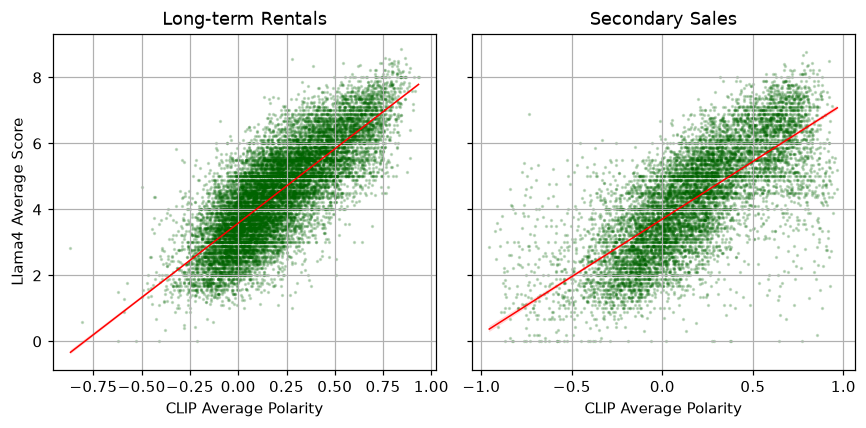

In [10]:
if llama is None:
    print(f"Figure 7 requires {llama_path}")
else:
    fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
    for ax, (market, title) in zip(axes, MARKETS.items()):
        data = llama.loc[llama["deal_type"].eq(market)].dropna(subset=["clip_polarity", "average_luxury_score"])
        sns.regplot(data=data, x="clip_polarity", y="average_luxury_score", ax=ax,
                    scatter_kws={"alpha": 0.2, "s": 1.5, "color": "darkgreen", "rasterized": True},
                    line_kws={"color": "red", "linewidth": 1.0})
        ax.set(title=title, xlabel="CLIP Average Polarity",
               ylabel="Llama4 Average Score" if ax is axes[0] else "")
        ax.grid(True)
    fig.tight_layout()
    save_figure(fig, figures_dir, "07")

### Figure 8. CLIP Q-score and property size

Plot style from the original hedonic notebook, cells 29, 40, and 41.

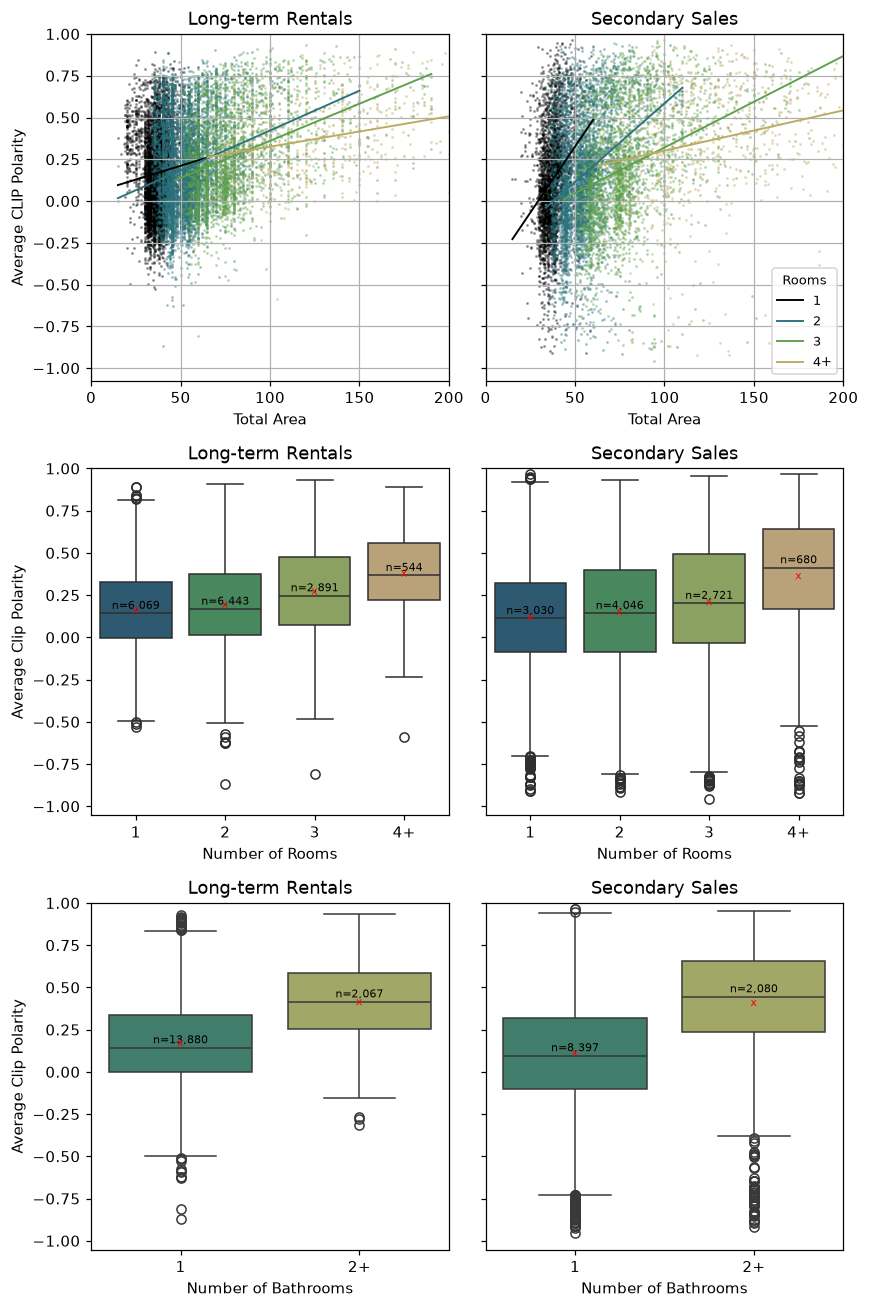

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12), sharey="row")
rooms = scored["roomsCount_grouped"].cat.categories
cmap = plt.get_cmap("gist_earth")
colors = [cmap(i / len(rooms)) for i in range(len(rooms))]

for column, (market, title) in enumerate(MARKETS.items()):
    data = scored.loc[scored["deal_type"].eq(market)]
    ax = axes[0, column]
    for room, color in zip(rooms, colors):
        subset = data.loc[data["roomsCount_grouped"].eq(room)]
        if subset.empty:
            continue
        sns.regplot(data=subset, x="totalArea", y="clip_polarity", ax=ax, ci=None,
                    scatter_kws={"color": color, "s": 1, "alpha": 0.3, "rasterized": True},
                    line_kws={"color": color, "linewidth": 1.25, "label": room})
    ax.set(title=title, xlabel="Total Area", xlim=(0, 200),
           ylabel="Average CLIP Polarity" if column == 0 else "")
    ax.grid(True)
    plot_categories(data, "roomsCount_grouped", "Number of Rooms", axes[1, column],
                    title=title, left=column == 0)
    plot_categories(data, "bathrooms_cat", "Number of Bathrooms", axes[2, column],
                    title=title, left=column == 0)
axes[0, 1].legend(title="Rooms", loc="lower right", fontsize="small", title_fontsize="small")
for row in axes:
    row[0].set_ylim(top=1.0)
fig.tight_layout()
save_figure(fig, figures_dir, "08")

### Figure 9. CLIP Q-score and property characteristics

Plot style from the original hedonic notebook, cells 54, 56, and 42.

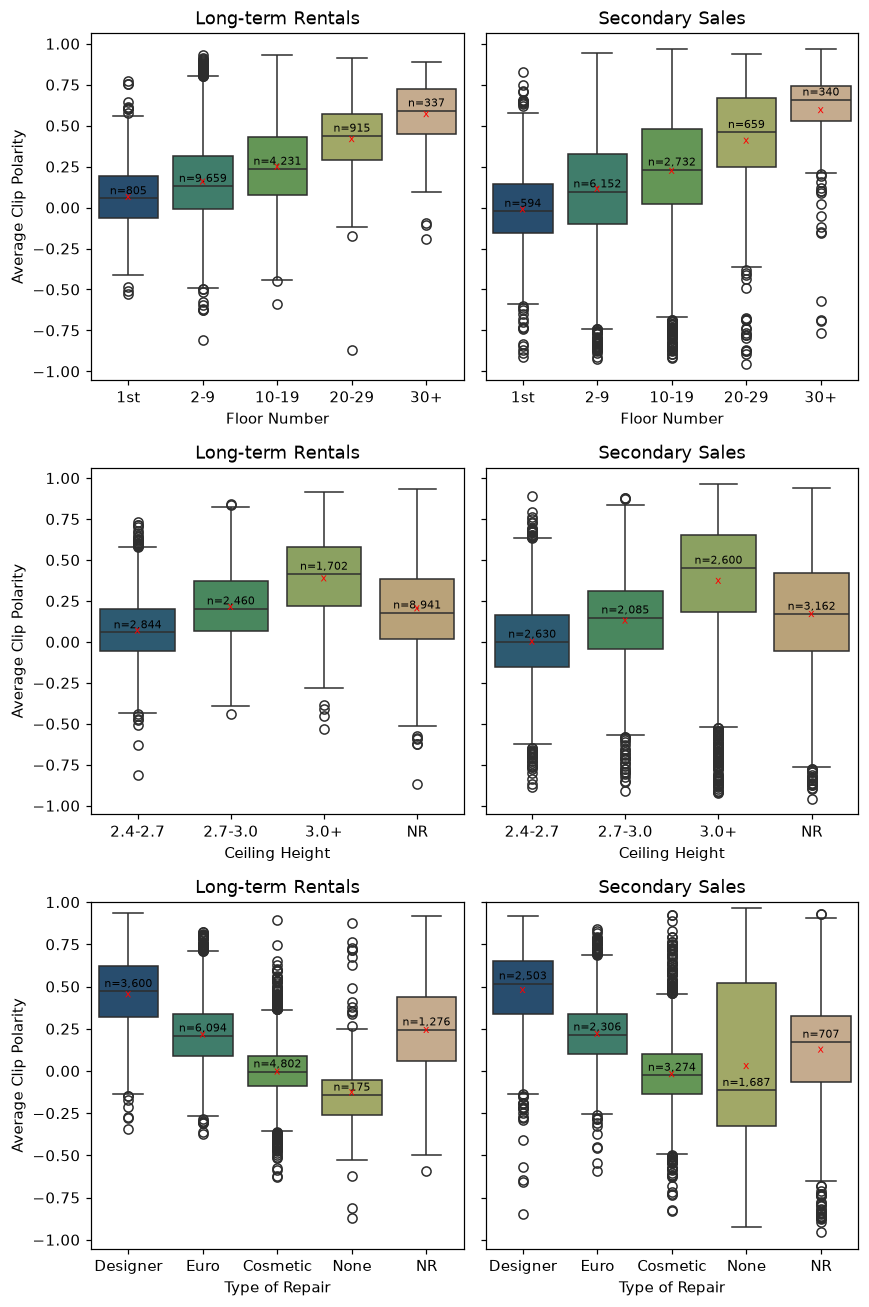

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12), sharey="row")
variables = [
    ("floorNumberCapped", "Floor Number"),
    ("ceilingHeightCapped", "Ceiling Height"),
    ("repairType", "Type of Repair"),
]
for column, (market, title) in enumerate(MARKETS.items()):
    data = scored.loc[scored["deal_type"].eq(market)]
    for row, (variable, label) in enumerate(variables):
        plot_categories(data, variable, label, axes[row, column], title=title, left=column == 0)
axes[-1, 0].set_ylim(top=1.0)
fig.tight_layout()
save_figure(fig, figures_dir, "09")

### Figure 10. Year of construction and CLIP

Plot style from the original hedonic notebook, cell 43.

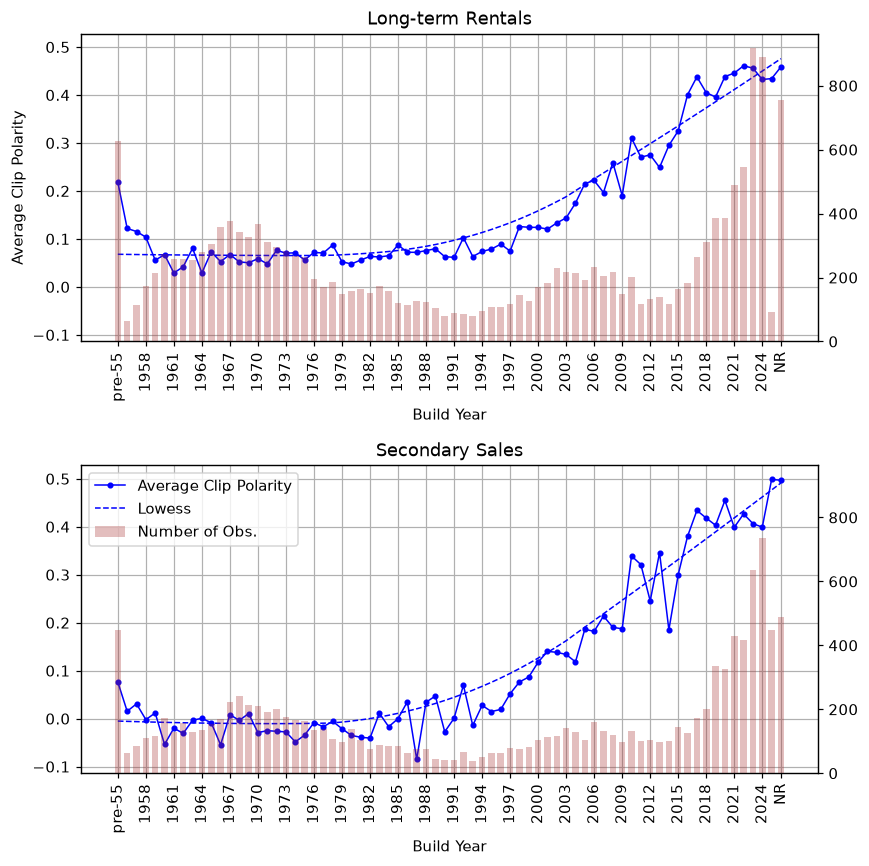

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharey=True)
count_axes = []
for ax, (market, title) in zip(axes, MARKETS.items()):
    data = listings.loc[listings["deal_type"].eq(market)]
    years = data.groupby("buildYearCapped", observed=False)["clip_polarity"].agg(["mean", "size"])
    year_labels = years.index.tolist()
    x = np.arange(len(years))
    average, = ax.plot(x, years["mean"], color="blue", label="Average Clip Polarity",
                       marker="o", linewidth=1, markersize=3)
    sns.regplot(x=x, y=years["mean"], ax=ax, lowess=True, scatter=False, label="Lowess",
                line_kws={"color": "blue", "linestyle": "--", "linewidth": 1})
    trend = ax.lines[-1]

    count_ax = ax.twinx()
    count_axes.append(count_ax)
    bars = count_ax.bar(x, years["size"], color="brown", alpha=0.3, width=0.7,
                        label="Number of Obs.")
    ticks = np.r_[x[::3], x[-1]] if x[-1] % 3 else x[::3]
    ax.set_xticks(ticks, [year_labels[i] for i in ticks], rotation=90)
    ax.set(title=title, xlabel="Build Year",
           ylabel="Average Clip Polarity" if ax is axes[0] else "")
    ax.grid(True)
    if ax is axes[1]:
        count_ax.legend(handles=[average, trend, bars], loc="upper left")

count_max = max(ax.get_ylim()[1] for ax in count_axes)
for ax in count_axes:
    ax.set_ylim(0, count_max)
fig.tight_layout()
save_figure(fig, figures_dir, "10")

### Figure 11. Moscow’s demolition program and CLIP

Plot style from the original hedonic notebook, cell 46.

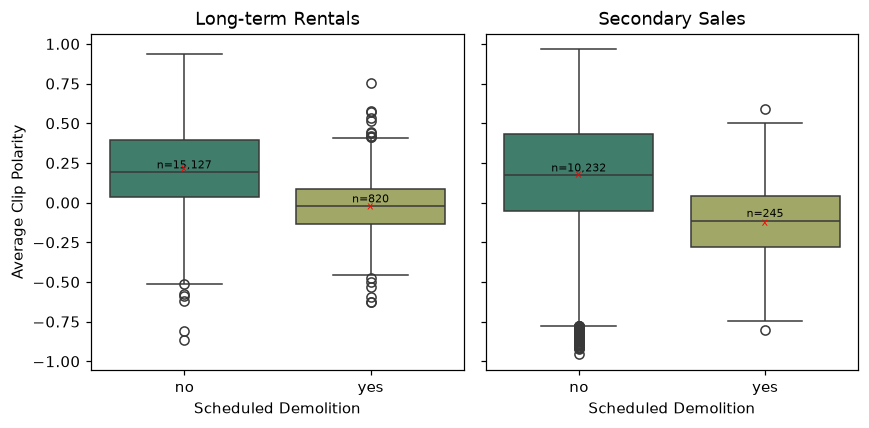

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
for ax, (market, title) in zip(axes, MARKETS.items()):
    data = scored.loc[scored["deal_type"].eq(market)]
    plot_categories(data, "toDemolish", "Scheduled Demolition", ax, title=title, left=ax is axes[0])
fig.tight_layout()
save_figure(fig, figures_dir, "11")

### Figure 12. Moscow districts and CLIP

Plot style from the original hedonic notebook, cells 64 and 65.

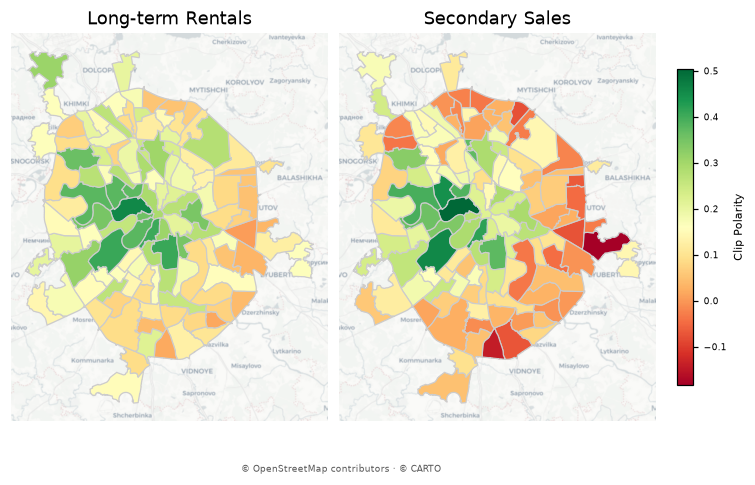

In [15]:
districts_path = inputs_dir / "moscow_administrative_districts.parquet"
if not districts_path.is_file():
    print(f"Figure 12 requires {districts_path}")
else:
    districts = gpd.read_parquet(districts_path, columns=["raion_rus", "geometry"])
    if districts.crs is None:
        raise ValueError(f"{districts_path} must contain a coordinate reference system")
    districts = districts.dissolve(by="raion_rus", as_index=False)
    points = gpd.GeoDataFrame(
        scored, geometry=gpd.points_from_xy(scored["lng"], scored["lat"]), crs=4326,
    ).to_crs(districts.crs)
    matched = points.sjoin(districts, predicate="intersects", how="inner")
    means = matched.groupby(["deal_type", "raion_rus"])["clip_polarity"].mean()
    if means.empty:
        raise ValueError(f"{districts_path} does not overlap the scored listings")

    cmap = "RdYlGn"
    norm = plt.Normalize(vmin=means.min(), vmax=means.max())
    fig, (ax1, ax2, legend_ax) = plt.subplots(
        1, 3, figsize=(8, 5), sharey=True, gridspec_kw={"width_ratios": [12, 12, 1]},
    )
    for ax, (market, title) in zip([ax1, ax2], MARKETS.items()):
        polygons = districts.join(means.loc[market], on="raion_rus").to_crs(3857)
        polygons.plot(column="clip_polarity", cmap=cmap, norm=norm, ax=ax,
                      edgecolor="0.8", linewidth=0.8, missing_kwds=missing)
        add_basemap(ax, figure_assets / "moscow_positron.png")
        ax.set_title(title)
        ax.set_axis_off()

    colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=legend_ax,
                            orientation="vertical", fraction=0.6, pad=0)
    colorbar.ax.tick_params(labelsize=6)
    colorbar.set_label("Clip Polarity", fontsize=7)
    legend_ax.set_axis_off()
    fig.text(0.5, 0.05, "© OpenStreetMap contributors · © CARTO",
             ha="center", fontsize=6, color="0.35")
    fig.subplots_adjust(wspace=0.05)
    save_figure(fig, figures_dir, "12", dpi=400)

## Price predictions and time on market

Figures 14–17 use the price and duration samples with adjusted Q from
finished interiors. Listings with missing exterior or floor-plan scores
are eligible.

In [16]:
from IPython.display import display
from utils.paper_models import (
    FEATURE_LABELS, PRICE_SCALE, boost_features, boosting_shap, fit_price_models, linear_shap,
    ols_features,
)
from utils.paper_survival import duration_sample, fit_cox_model

price_labels = {
    "long_rent": "Log Price (rub thousands)",
    "sale_secondary": "Log Price (rub millions)",
}

### Figure 13. CLIP and asking prices

Plot style from the original hedonic notebook, cell 67.

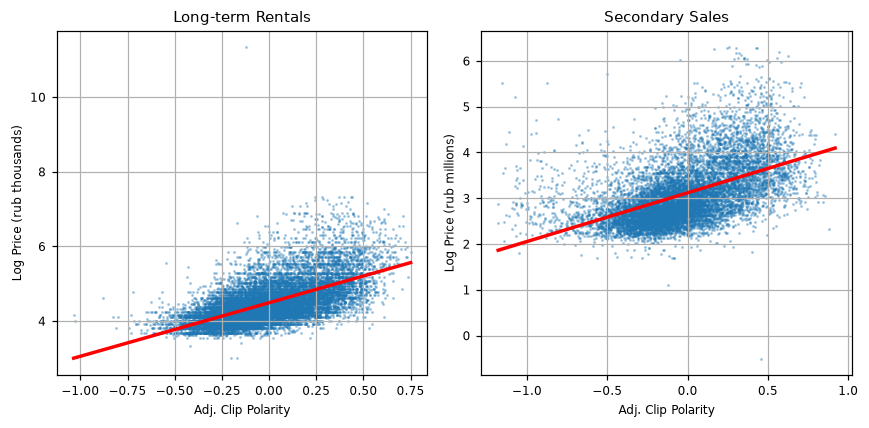

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (market, title) in zip(axes, MARKETS.items()):
    data = listings.loc[listings["deal_type"].eq(market) & listings["price_last"].gt(0)]
    data = data.dropna(subset=["clip_polarity_adj"])
    log_price = np.log(data["price_last"] / PRICE_SCALE[market])
    sns.regplot(data=data, x="clip_polarity_adj", y=log_price, ax=ax,
                scatter_kws={"alpha": 0.3, "s": 1, "rasterized": True},
                line_kws={"color": "red"})
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Adj. Clip Polarity", fontsize=8)
    ax.set_ylabel(price_labels[market], fontsize=8)
    ax.tick_params(labelsize=8)
    ax.grid(True)
fig.tight_layout()
save_figure(fig, figures_dir, "13")

### Figure 14. Partial dependence on the interior Q-score

Plot style from the original hedonic notebook, cell 139.

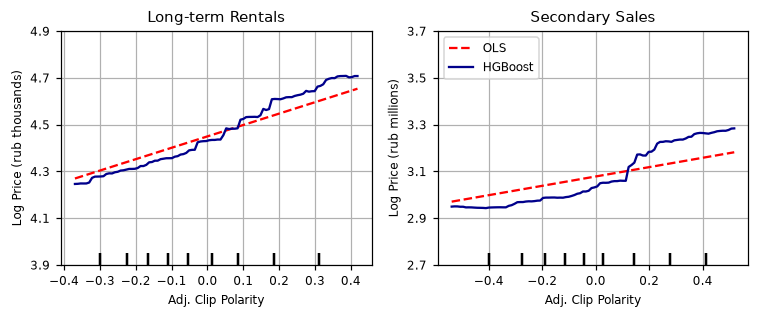

In [18]:
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LinearRegression

fits = {market: fit_price_models(listings, market, specifications=(2,)) for market in MARKETS}
limits = {"long_rent": (3.9, 4.9), "sale_secondary": (2.7, 3.7)}
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, (market, title) in zip(axes, MARKETS.items()):
    train, test, models = fits[market]
    full = models[2]
    feature = "clip_polarity_adj"
    train_ols = ols_features(full["design_info"], train).drop(columns="Intercept")
    test_ols = ols_features(full["design_info"], test).drop(columns="Intercept")
    ols = LinearRegression().fit(train_ols, train["log_price"])
    ols_display = PartialDependenceDisplay.from_estimator(
        ols, test_ols, features=[feature], kind="average", grid_resolution=100, ax=ax,
        pd_line_kw={"color": "red", "linestyle": "--", "label": "OLS"},
    )

    columns = full["features"]
    test_hgb = boost_features(test, columns).to_numpy()
    hgb_display = PartialDependenceDisplay.from_estimator(
        full["hgb"], test_hgb, features=[columns.index(feature)], feature_names=columns,
        kind="average", grid_resolution=100, ax=ols_display.axes_,
        line_kw={"label": "HGBoost", "color": "darkblue"},
    )
    ols_line = ols_display.lines_[0, 0]
    hgb_line = hgb_display.lines_[0, 0]
    # Restore the training mean omitted by tree recursion, as in the source plot.
    hgb_line.set_ydata(hgb_line.get_ydata() + train["log_price"].mean())

    panel = hgb_display.axes_[0, 0]
    lower, upper = limits[market]
    panel.set_yticks(np.arange(lower, upper + 0.01, 0.2))
    y = np.r_[ols_line.get_ydata(), hgb_line.get_ydata()]
    panel.set_ylim(min(lower, y.min()), max(upper, y.max()))
    tick_step = 0.2 if np.ptp(hgb_line.get_xdata()) > 0.9 else 0.1
    panel.xaxis.set_major_locator(MultipleLocator(tick_step))
    panel.set_title(title, fontsize=10)
    panel.set_xlabel("Adj. Clip Polarity", fontsize=8)
    panel.set_ylabel(price_labels[market], fontsize=8)
    panel.tick_params(labelsize=8)
    panel.grid(True)
    if market == "sale_secondary":
        panel.legend(loc="upper left", fontsize=8)
    elif panel.get_legend() is not None:
        panel.get_legend().remove()

fig.tight_layout()
save_figure(fig, figures_dir, "14")

### Figure 15. Shapley values

The OLS panel explains the separate source linear model with apartment and
demolition controls. It uses LinearExplainer and the background limits of
12,708 rows for rentals and 8,812 for sales. The boosting panel uses
TreeExplainer. Both explain the full test split.

Plot style from the original hedonic notebook, cells 130 and 133.

,OLS,Gradient boosting
Rooms,0.0503,0.0498
Bathrooms,0.0157,0.0205
Material,0.0072,0.0052
Missing year built,0.0020,0.0003
Scheduled demolition,0.0020,0.0044
Photo count,0.0120,0.0115
Apartment status,0.0080,0.0039
State of repair,0.0470,0.0570
Floor number,0.0048,0.0036
Ceiling height,0.0099,0.0063


,OLS,Gradient boosting
Rooms,0.0122,0.0257
Bathrooms,0.0036,0.0432
Material,0.0106,0.0205
Missing year built,0.0001,0.0004
Scheduled demolition,0.0051,0.0035
Photo count,0.0080,0.0069
Apartment status,0.0193,0.0132
State of repair,0.0496,0.0551
Floor number,0.0102,0.0085
Ceiling height,0.0231,0.0207


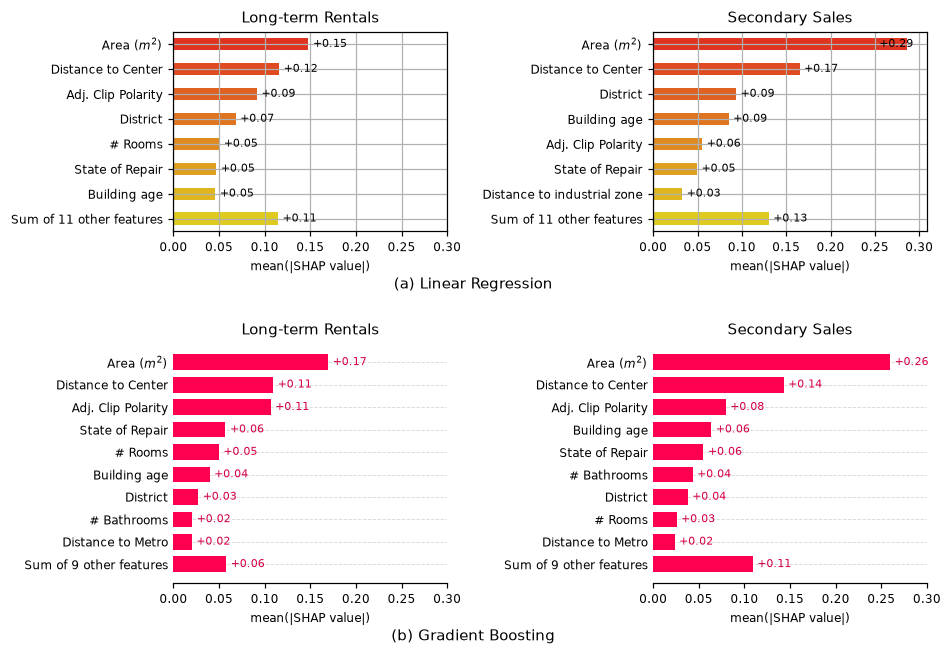

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(8.8, 6.2), gridspec_kw={"height_ratios": [1, 1.2]})
plot_labels = {
    **FEATURE_LABELS,
    "totalArea": r"Area ($m^2$)",
    "clip_polarity_adj": "Adj. Clip Polarity",
    "distance_center": "Distance to Center",
    "distance_metro": "Distance to Metro",
    "repairType": "State of Repair",
    "bathrooms_cat": "# Bathrooms",
    "roomsCount_grouped": "# Rooms",
}

for column, (market, title) in enumerate(MARKETS.items()):
    train, test, models = fits[market]
    full = models[2]
    ols_importance = linear_shap(train, test, market)
    hgb_importance = boosting_shap(full["hgb"], test, full["features"])
    display(pd.DataFrame({"OLS": ols_importance, "Gradient boosting": hgb_importance})
            .rename(index=FEATURE_LABELS).round(4))

    for row, (importance, limit) in enumerate([(ols_importance, 7), (hgb_importance, 9)]):
        ax = axes[row, column]
        top = importance.nlargest(limit).rename(index=plot_labels)
        rest = importance.drop(index=importance.nlargest(limit).index)
        top.loc[f"Sum of {len(rest)} other features"] = rest.sum()
        plot_data = top.rename_axis("feature").reset_index(name="value")
        if row == 0:
            sns.barplot(data=plot_data, x="value", y="feature", hue="feature",
                        palette="autumn", width=0.5, legend=False, ax=ax)
            ax.grid(True)
        else:
            ax.barh(plot_data["feature"], plot_data["value"], height=0.7, color="#ff0051")
            ax.invert_yaxis()
            ax.spines[["top", "right", "left"]].set_visible(False)
            ax.grid(axis="y", linestyle="--", linewidth=0.6, color="0.85")
            ax.set_axisbelow(True)
            ax.tick_params(axis="y", length=0)

        xmax = max(0.3, top.max() * 1.08)
        ax.set_xlim(0, xmax)
        ax.xaxis.set_major_locator(MultipleLocator(0.05))
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("mean(|SHAP value|)", fontsize=8)
        ax.set_ylabel("")
        ax.tick_params(labelsize=8)
        for i, value in enumerate(top):
            offset = -xmax * 0.1 if row == 0 and value >= xmax * 0.7 else 0.005
            color = "black" if row == 0 else "#d50043"
            ax.text(value + offset, i, f"+{value:.2f}", va="center", fontsize=7, color=color)
fig.tight_layout(rect=(0, 0.05, 1, 1), h_pad=3.2)
for row, label in enumerate(["(a) Linear Regression", "(b) Gradient Boosting"]):
    fig.text(0.5, axes[row, 0].get_position().y0 - 0.084, label, ha="center", fontsize=10)
save_figure(fig, figures_dir, "15")

### Figure 16. Kaplan–Meier curves by CLIP quartile

Plot style from the original hedonic notebook, cell 163.

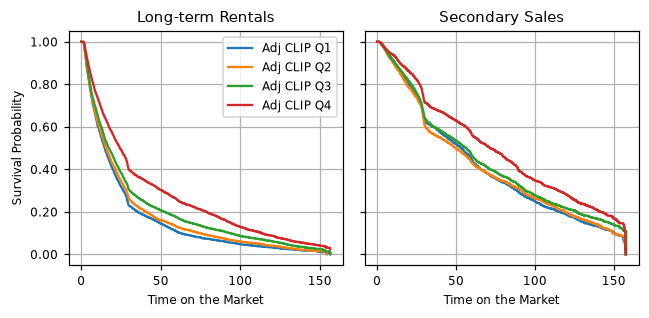

In [20]:
from matplotlib.ticker import FormatStrFormatter
from statsmodels.duration.survfunc import SurvfuncRight

durations = {market: duration_sample(listings, market) for market in MARKETS}
fig, axes = plt.subplots(1, 2, figsize=(6, 3), sharey=True)
quartiles = ["Adj CLIP Q1", "Adj CLIP Q2", "Adj CLIP Q3", "Adj CLIP Q4"]
for ax, (market, title) in zip(axes, MARKETS.items()):
    data = durations[market].copy()
    data["clip_Q"] = pd.qcut(data["clip_polarity_adj"], 4, labels=quartiles)
    for label, group in data.groupby("clip_Q", observed=True):
        km = SurvfuncRight(group["dur"], group["status"].astype(int))
        ax.step(np.r_[0, km.surv_times, group["dur"].max()],
                np.r_[1, km.surv_prob, km.surv_prob[-1]], where="post", label=label)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Time on the Market", fontsize=8)
    ax.set_xticks(np.arange(0, 176, 50))
    ax.tick_params(labelsize=8)
    ax.grid(True)
axes[0].set_ylabel("Survival Probability", fontsize=8)
axes[0].set_yticks(np.arange(0, 1.1, 0.2))
axes[0].yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
axes[0].legend(loc="upper right", fontsize=8)
fig.tight_layout()
save_figure(fig, figures_dir, "16")

### Figure 17. Proportional hazards model

Plot style from the original hedonic notebook, cells 170 and 172.

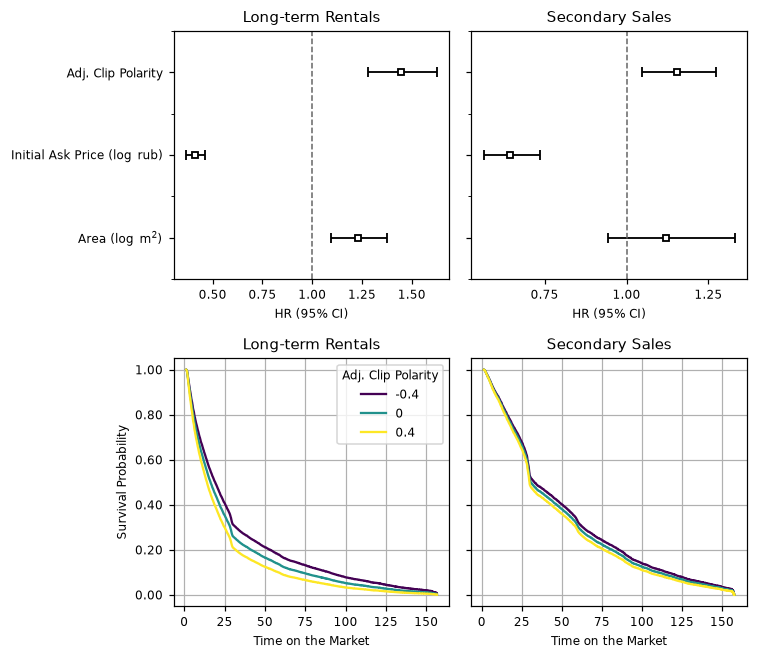

In [21]:
hazards = {market: fit_cox_model(data) for market, data in durations.items()}
fig, axes = plt.subplots(2, 2, figsize=(7, 6.1), sharey="row")
terms = {
    "clip_polarity_adj": "Adj. Clip Polarity",
    "np.log(price_first)": r"Initial Ask Price ($\log$ rub)",
    "np.log(totalArea)": r"Area ($\log$ m$^2$)",
}
positions = np.arange(len(terms))[::-1]
levels = [-0.4, 0.0, 0.4]

for column, (market, title) in enumerate(MARKETS.items()):
    fit = hazards[market]
    ratios = fit.hazard_ratios_.loc[list(terms)]
    lower, upper = np.exp(fit.confidence_intervals_.loc[list(terms)].to_numpy()).T
    ax = axes[0, column]
    ax.errorbar(ratios, positions, xerr=[ratios - lower, upper - ratios],
                fmt="s", color="black", markerfacecolor="white", markeredgewidth=1.2,
                markersize=4.5, capsize=3, linewidth=1.2)
    ax.axvline(1, linestyle="--", color="0.4", linewidth=1)
    ax.xaxis.set_major_locator(MultipleLocator(0.25))
    ax.set_yticks(positions, list(terms.values()))
    ax.set_ylim(-0.5, len(terms) - 0.5)
    ax.set_xlabel("HR (95% CI)", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.tick_params(labelsize=8)

    ax = axes[1, column]
    fit.plot_partial_effects_on_outcome(
        "clip_polarity_adj", values=levels, cmap="viridis", ax=ax, plot_baseline=False,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Time on the Market", fontsize=8)
    ax.set_xticks(np.arange(0, 160, 25))
    ax.tick_params(labelsize=8)
    ax.grid(True)

axes[1, 0].set_ylabel("Survival Probability", fontsize=8)
axes[1, 0].set_yticks(np.arange(0, 1.1, 0.2))
axes[1, 0].yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
handles, _ = axes[1, 0].get_legend_handles_labels()
axes[1, 0].legend(handles, [f"{score:g}" for score in levels], title="Adj. Clip Polarity",
                  title_fontsize=8, fontsize=8, loc="upper right")
axes[1, 1].get_legend().remove()
fig.tight_layout()
save_figure(fig, figures_dir, "17")

## Appendix

### Figure A.1. Distributions of LLaMA4 and CLIP scores

Plot style from the original hedonic notebook, cell 28.

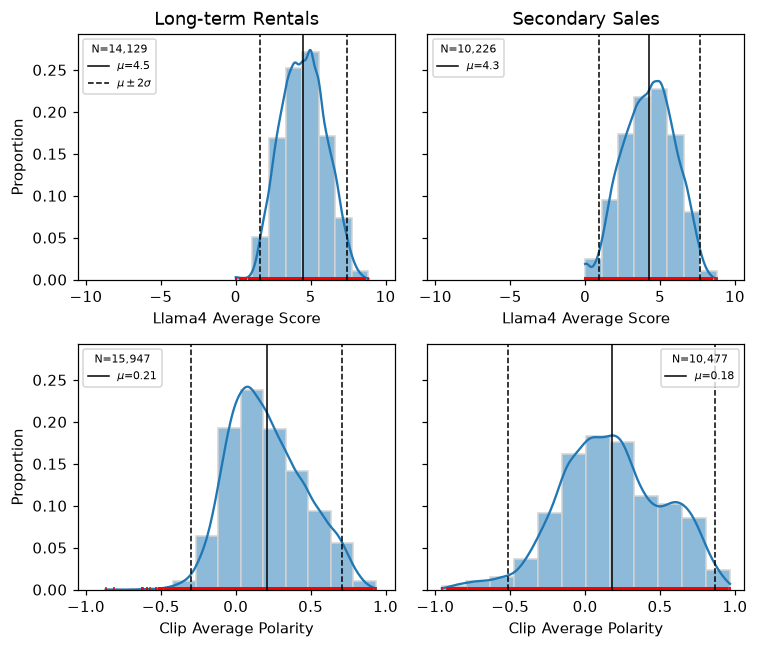

In [22]:
if llama is None:
    print(f"Figure A.1 requires {llama_path}")
else:
    fig, axes = plt.subplots(2, 2, figsize=(7, 6), sharey=True)
    for column, (market, title) in enumerate(MARKETS.items()):
        data = llama.loc[llama["deal_type"].eq(market)]
        axes[0, column].set_title(title)
        for row, (field, label, bins, decimals) in enumerate([
            ("average_luxury_score", "Llama4 Average Score", 8, 1),
            ("clip_polarity", "Clip Average Polarity", 12, 2),
        ]):
            ax = axes[row, column]
            values = data[field].dropna()
            if not values.empty:
                sns.histplot(values, bins=bins, stat="proportion", kde=True, edgecolor="lightgray", ax=ax)
                sns.rugplot(values, height=0.01, color="red", ax=ax, rasterized=True)
                mean, sigma = values.mean(), values.std()
                ax.axvline(mean, color="black", linewidth=1, label=rf"$\mu$={mean:.{decimals}f}")
                ax.axvline(mean - 2 * sigma, color="black", linestyle="--", linewidth=1)
                label_sigma = r"$\mu\pm2\sigma$" if row == 0 and column == 0 else None
                ax.axvline(mean + 2 * sigma, color="black", linestyle="--", linewidth=1, label=label_sigma)
                ax.legend(title=f"N={len(values):,}", fontsize="x-small", title_fontsize="x-small")
            ax.set_xlabel(label)

    lower = min(ax.get_xlim()[0] for ax in axes[1])
    upper = max(ax.get_xlim()[1] for ax in axes[1])
    for ax in axes[1]:
        ax.set_xlim(lower, upper)
    for ax in axes[0]:
        ax.set_xlim(lower * 10, upper * 10)
    fig.tight_layout()
    save_figure(fig, figures_dir, "A1")

## Photo-score variants

A is the interior specification above. B uses exterior Q, C uses floor-plan Q, and D includes all three Q-scores. E uses mean unfinished probability and F includes all four scores.

The combined PDFs use a page per score for descriptive plots, partial dependence and Kaplan–Meier curves. Their price and Cox results use all specified scores jointly.

In [23]:
from utils.paper_variant_plots import export_variant_figures

export_variant_figures(figures_dir, inputs_dir, listings, photo_types, quality_models_by_type)

Saved Figures 05–17 and A1 for variant B
Saved Figures 05–17 and A1 for variant C
Saved Figures 05–17 and A1 for variant D
Saved Figures 05–17 and A1 for variant E
Saved Figures 05–17 and A1 for variant F
